# EDA изображений: ISIC 2024 (только train)
Анализ самих снимков (кропы поражений 3D TBP). План: 1) выборка, 2) размеры, 3) яркость, цвет, контраст по классам, 4) примеры и крайние случаи, 5) средние изображения, 6) нормализация по цвету и яркости, 7) выводы.

Читать все 401 059 снимков долго, поэтому берём **все malignant (393) + случайные 3 000 benign**.

In [5]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import cv2

sns.set_theme(style="whitegrid")
ROOT = Path("../data/raw/task_2024/isic-2024-challenge")
IMG_DIR = ROOT / "train-image" / "image"
df = pd.read_csv(ROOT / "train-metadata.csv", usecols=["isic_id", "target", "patient_id"], low_memory=False)

mal = df[df.target == 1]
ben = df[df.target == 0].sample(3000, random_state=42)
smp = pd.concat([mal, ben]).reset_index(drop=True)
# не листаем папку (401 тыс. файлов, на диске это ~30 мин): число снимков берём из csv
print(smp.target.value_counts().to_dict(), "| снимков в train-metadata.csv:", len(df))

{0: 3000, 1: 393} | снимков в train-metadata.csv: 401059


## 1. Размеры и статистики по снимкам

In [6]:
def stats(i):
    im = np.asarray(Image.open(IMG_DIR / f"{i}.jpg").convert("RGB"))
    h, w = im.shape[:2]
    g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    r, gr, b = im.reshape(-1, 3).mean(0)
    return dict(w=w, h=h, R=r, G=gr, B=b, bright=g.mean(), contrast=g.std(),
                sharp=cv2.Laplacian(g, cv2.CV_64F).var())

feat = pd.DataFrame([stats(i) for i in smp.isic_id])
feat = pd.concat([smp[["isic_id", "target"]], feat], axis=1)
feat["label"] = feat.target.map({0: "benign", 1: "malignant"})
print("квадратные:", (feat.w == feat.h).mean() * 100, "%")
feat[["w", "h"]].describe().loc[["min", "50%", "max", "mean"]].round(1)

квадратные: 100.0 %


,w,h
min,65.0,65.0
50%,131.0,131.0
max,237.0,237.0
mean,133.1,133.1


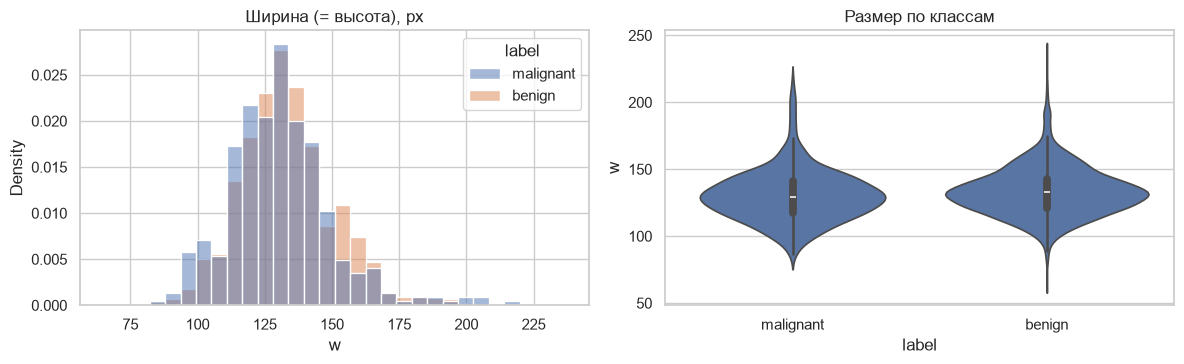

            count   mean   std   min    25%    50%    75%    max
label                                                           
benign     3000.0  133.4  18.1  65.0  121.0  133.0  143.0  237.0
malignant   393.0  130.6  19.3  87.0  117.0  129.0  141.0  215.0


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(data=feat, x="w", hue="label", stat="density", common_norm=False, bins=30, ax=ax[0]); ax[0].set_title("Ширина (= высота), px")
sns.violinplot(data=feat, x="label", y="w", ax=ax[1]); ax[1].set_title("Размер по классам")
plt.tight_layout(); plt.show()
print(feat.groupby("label").w.describe().round(1))

Все снимки квадратные, но размер варьируется: 65–237 px, медиана 131. По классам распределения почти совпадают (медиана 129 у malignant против 133 у benign), то есть размер кропа в пикселях классы практически не разделяет.

## 1б. Качество снимков: дубликаты и артефакты
Проверяем на выборке: точные дубликаты (md5 файла), почти-дубликаты (perceptual dHash, расстояние Хэмминга ≤ 4 из 64) и простые прокси артефактов: волосы (blackhat-фильтр), чёрные поля, пересвеченные блики, яркость углов.

In [8]:
import hashlib

def load_img(i): return np.asarray(Image.open(IMG_DIR / f"{i}.jpg").convert("RGB"))

def dhash(im, s=8):
    g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    g = cv2.resize(g, (s + 1, s), interpolation=cv2.INTER_AREA)
    return (g[:, 1:] > g[:, :-1]).ravel()

HAIR_K = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))

def quality(i):
    p = IMG_DIR / f"{i}.jpg"
    md5 = hashlib.md5(p.read_bytes()).hexdigest()
    im = np.asarray(Image.open(p).convert("RGB"))
    g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    h, w = g.shape; k = max(h // 5, 1)
    corners = np.mean([g[:k, :k].mean(), g[:k, -k:].mean(), g[-k:, :k].mean(), g[-k:, -k:].mean()])
    hair = (cv2.morphologyEx(g, cv2.MORPH_BLACKHAT, HAIR_K) > 15).mean()   # тонкие тёмные линии
    return dict(md5=md5, hair=hair, corner=corners,
                sat=(g >= 250).mean(), dark=(g <= 30).mean()), dhash(im)

res = [quality(i) for i in feat.isic_id]
qual = pd.DataFrame([r[0] for r in res]); H = np.array([r[1] for r in res], dtype=np.float32)
feat = feat.drop(columns=[c for c in qual.columns if c in feat.columns]).join(qual)
feat["patient_id"] = smp.patient_id.values

# 1) точные дубликаты (по байтам файла)
print("точных дубликатов файлов:", feat.md5.duplicated().sum())

# 2) почти-дубликаты: расстояние Хэмминга между dHash <= 4 из 64 бит
D = 64 - (H @ H.T + (1 - H) @ (1 - H.T))
iu = np.triu_indices(len(H), k=1)
near = np.argwhere((D <= 4) & (np.triu(np.ones_like(D), 1) > 0))
print("пар почти-дубликатов (dHash<=4):", len(near),
      "| из них с одним пациентом:", sum(feat.patient_id[a] == feat.patient_id[b] for a, b in near))

# 3) артефакты: доли пикселей / признаки по классам
print(feat.groupby("label")[["hair", "corner", "sat", "dark"]].describe().T.round(3).loc[(slice(None), ["mean", "50%", "max"]), :])

# доли проблемных снимков (пороги подобраны по примерам ниже)
flags = pd.DataFrame({"много волос (hair>0.3)": feat.hair > 0.3,
                      "чёрные поля (dark>0.02)": feat.dark > 0.02,
                      "блики (sat>0.0005)": feat.sat > 0.0005})
flags["label"] = feat.label
print((flags.groupby("label").mean() * 100).round(2).T.assign(всего=(flags.drop(columns="label").mean() * 100).round(2)))

точных дубликатов файлов: 0
пар почти-дубликатов (dHash<=4): 1 | из них с одним пациентом: 0
label         benign  malignant
hair   mean    0.103      0.133
       50%     0.066      0.096
       max     0.703      0.655
corner mean  144.157    139.069
       50%   145.661    140.919
       max   227.285    209.638
sat    mean    0.000      0.000
       50%     0.000      0.000
       max     0.174      0.001
dark   mean    0.004      0.006
       50%     0.000      0.000
       max     0.415      0.287
label                    benign  malignant  всего
много волос (hair>0.3)     6.33      10.94   6.87
чёрные поля (dark>0.02)    2.43       4.58   2.68
блики (sat>0.0005)         0.10       0.25   0.12


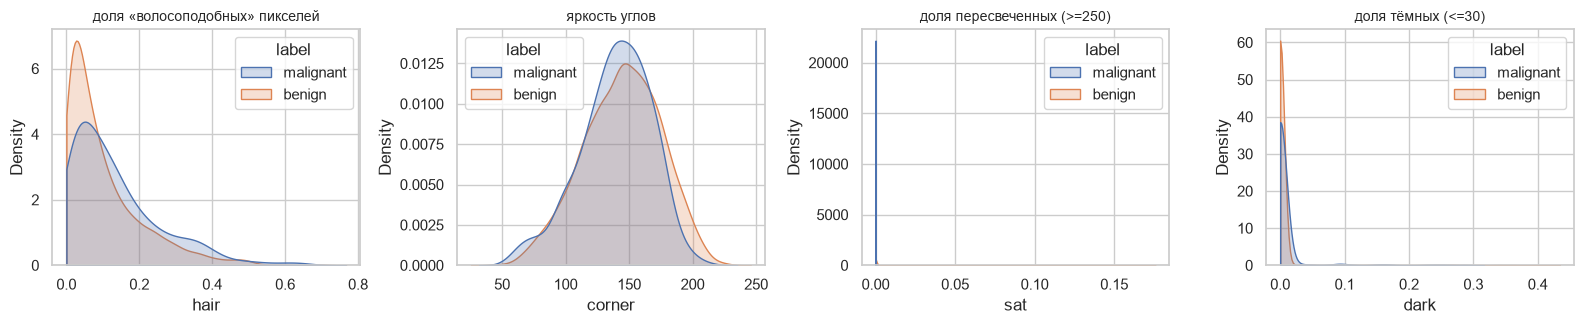

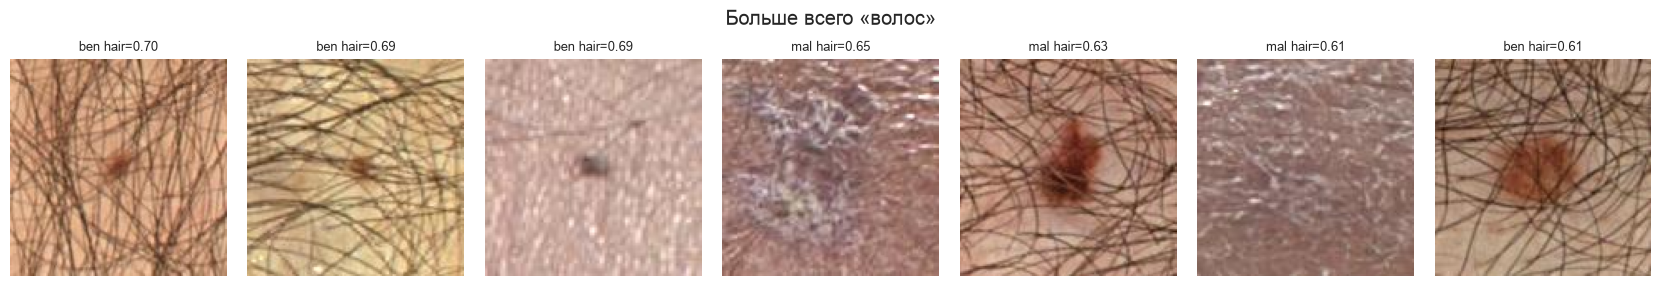

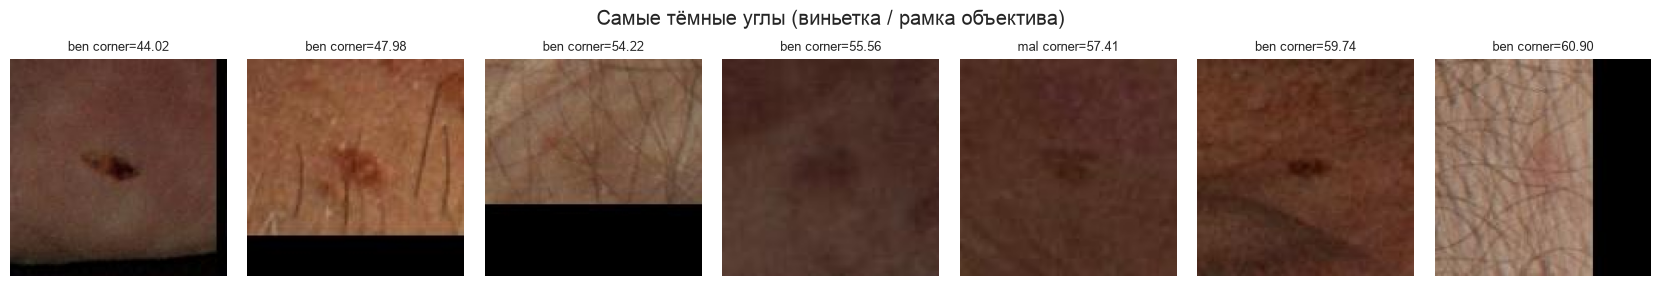

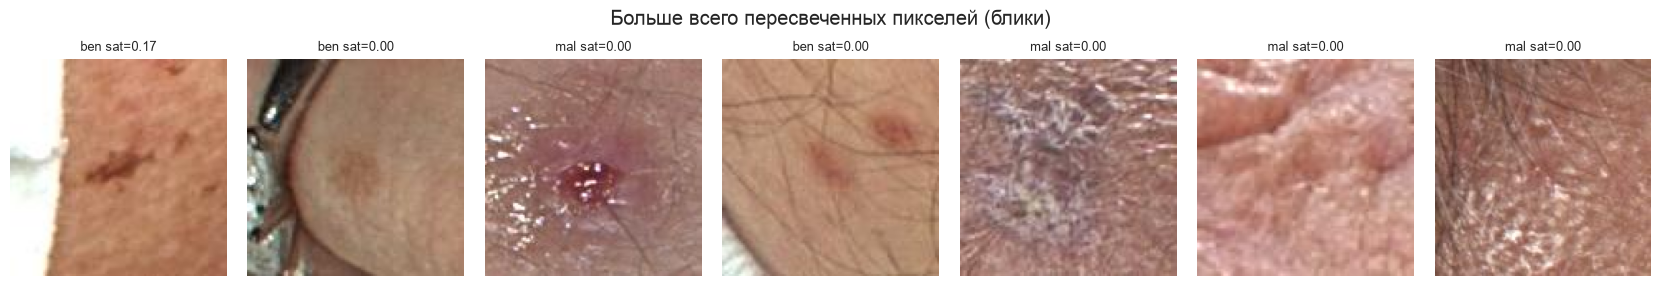

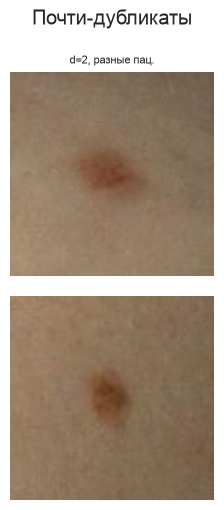

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for a, (c, t) in zip(axes, [("hair", "доля «волосоподобных» пикселей"), ("corner", "яркость углов"),
                           ("sat", "доля пересвеченных (>=250)"), ("dark", "доля тёмных (<=30)")]):
    sns.kdeplot(data=feat, x=c, hue="label", common_norm=False, fill=True, clip=(0, None) if c != "corner" else None, ax=a, warn_singular=False)
    a.set_title(t, fontsize=10)
plt.tight_layout(); plt.show()

def show(ids, title, extra=None):
    fig, axes = plt.subplots(1, len(ids), figsize=(2.4 * len(ids), 2.9))
    for a, i in zip(np.atleast_1d(axes), ids):
        a.imshow(load_img(i)); a.axis("off")
        r = feat[feat.isic_id == i].iloc[0]
        a.set_title(f"{r.label[:3]} {extra}={r[extra]:.2f}" if extra else r.label, fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()


show(feat.nlargest(7, "hair").isic_id, "Больше всего «волос»", "hair")
show(feat.nsmallest(7, "corner").isic_id, "Самые тёмные углы (виньетка / рамка объектива)", "corner")
show(feat.nlargest(7, "sat").isic_id, "Больше всего пересвеченных пикселей (блики)", "sat")
if len(near):
    k = min(len(near), 6)
    fig, axes = plt.subplots(2, k, figsize=(2.4 * k, 5.2), squeeze=False)
    for c, (a, b) in enumerate(near[:k]):
        for r, j in enumerate((a, b)):
            axes[r, c].imshow(load_img(feat.isic_id[j])); axes[r, c].axis("off")
        axes[0, c].set_title(f"d={int(D[a, b])}, {'один' if feat.patient_id[a] == feat.patient_id[b] else 'разные'} пац.", fontsize=8)
    fig.suptitle("Почти-дубликаты"); plt.tight_layout(); plt.show()

**Выводы по качеству:**
- Все 3 393 файла открылись без ошибок, **точных дубликатов нет**. Единственная пара почти-дубликатов (dHash ≤ 4) при просмотре оказалась ложным срабатыванием: разные поражения, разные пациенты. Ограничение: выборка случайная (≈0.8% от 401 тыс.), поэтому повторные снимки одного и того же поражения/пациента здесь почти не встречаются. Проверка на утечку делается только на полном наборе с группировкой по `patient_id`.
- **Волосы** — самый частый артефакт: >30% «волосоподобных» пикселей у 6.3% benign и 10.9% malignant (6.9% всего). Волосы местами полностью закрывают поражение.
- **Чёрные поля** (кроп вышел за границу исходного кадра, доля чёрного >2%): 2.4% benign и 4.6% malignant. Это заливка, а не кожа, её стоит маскировать или обрезать, иначе она искажает статистики яркости и контраста.
- **Блики** на уровне единиц снимков (0.1% и 0.25%), на обучение почти не влияют.
- Волосы и чёрные поля чаще встречаются у malignant (разница в несколько процентных пунктов). Это возможный побочный сигнал («шорткат»), который модель может использовать вместо самого поражения. Нужна аугментация (в т.ч. искусственные волосы, cutout) и проверка по срезам. Пороги подобраны по примерам, это грубые прокси, а не точная разметка артефактов.

## 2. Яркость, цвет, контраст, резкость по классам

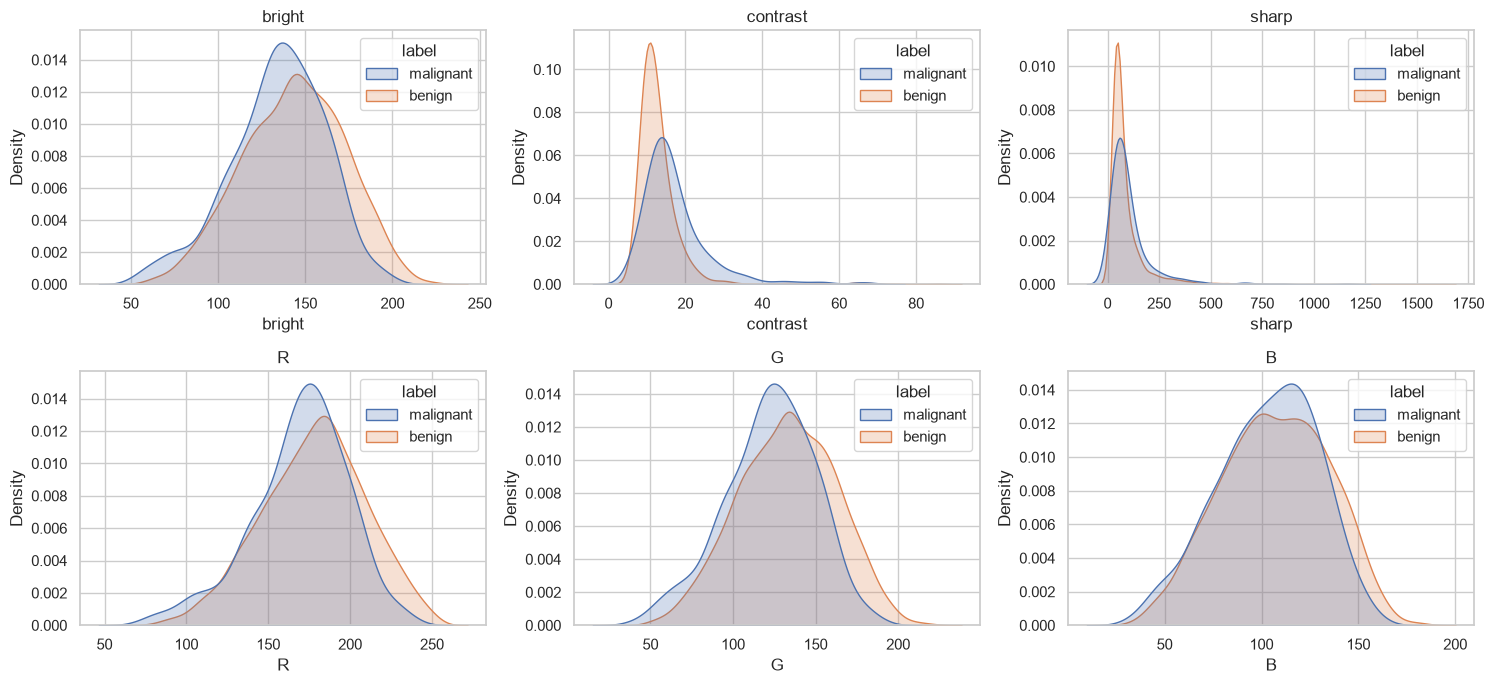

           bright  contrast  sharp      R      G      B
label                                                  
benign      144.4      11.6   55.8  179.9  133.7  107.6
malignant   135.5      15.0   71.9  172.6  123.5  104.9


In [10]:
cols = ["bright", "contrast", "sharp", "R", "G", "B"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(axes.ravel(), cols):
    sns.kdeplot(data=feat, x=c, hue="label", common_norm=False, fill=True, ax=a, warn_singular=False)
    a.set_title(c)
plt.tight_layout(); plt.show()
print(feat.groupby("label")[cols].median().round(1))

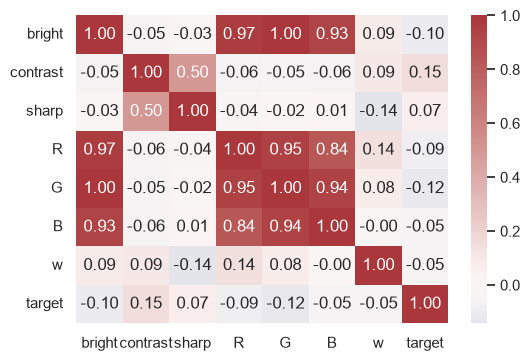

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(feat[cols + ["w", "target"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax); plt.show()

Malignant в среднем темнее (яркость 136 против 144), контрастнее (15 против 12) и резче (Laplacian 72 против 56); по каналам R и G тоже ниже. Распределения сильно перекрываются, поэтому простые статистики классы не разделяют. Разброс яркости и цвета между снимками заметный → нужна нормализация и цветовые аугментации.

## 3. Примеры изображений

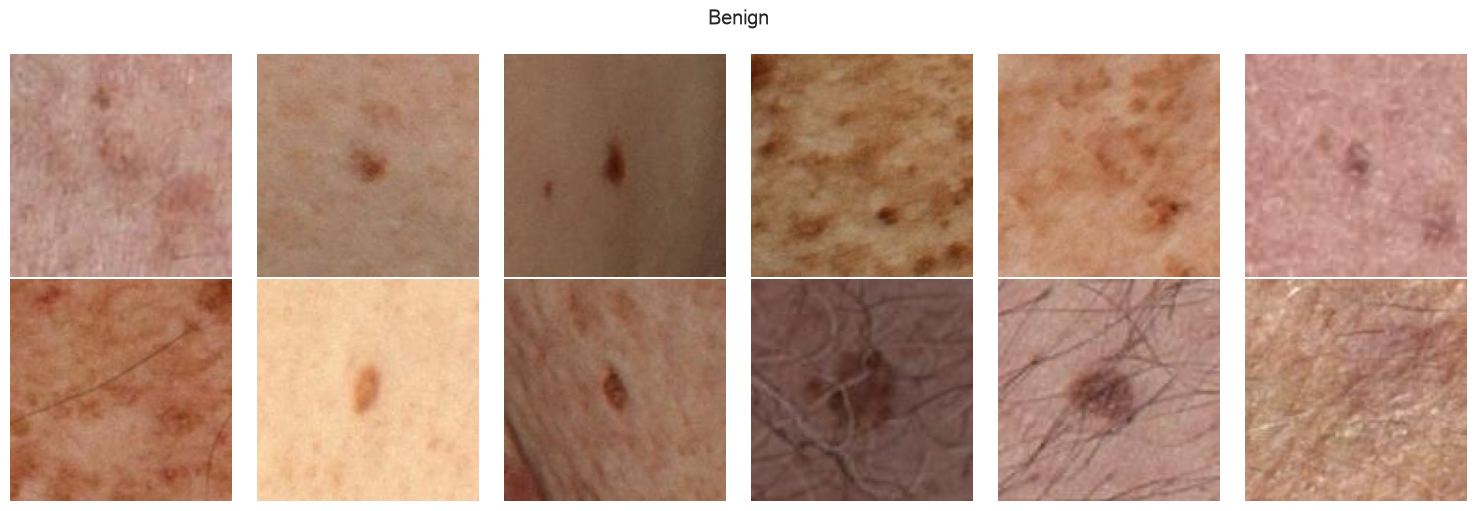

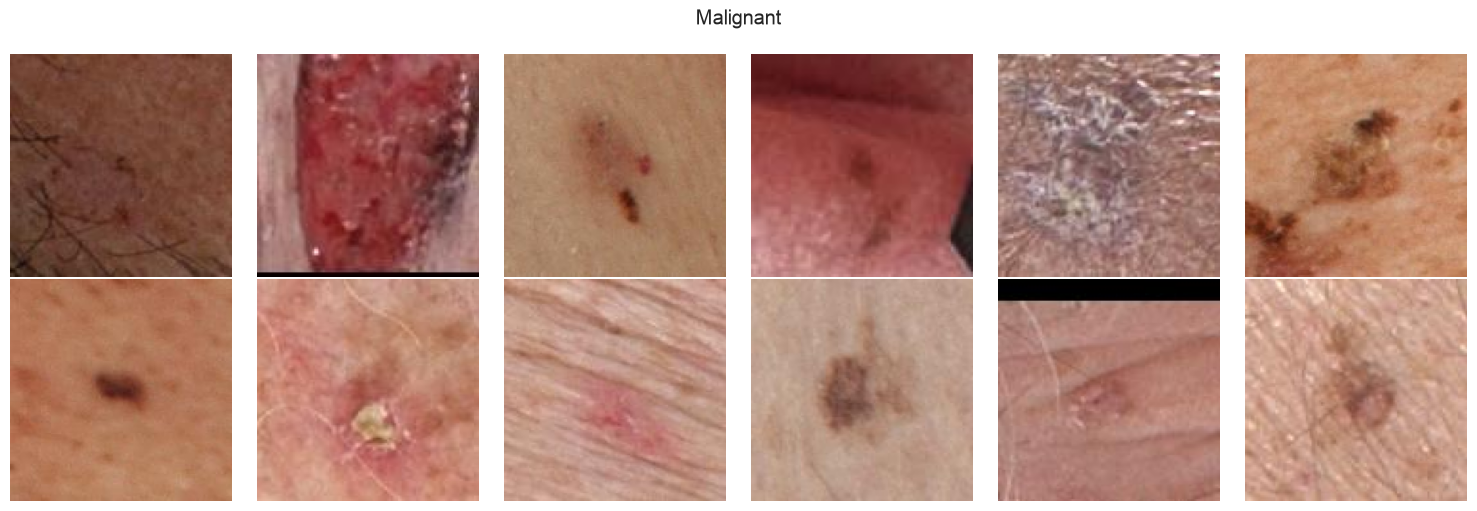

In [12]:
def grid(ids, title, n=12):
    fig, axes = plt.subplots(2, n // 2, figsize=(15, 5.2))
    for a, i in zip(axes.ravel(), ids[:n]):
        a.imshow(Image.open(IMG_DIR / f"{i}.jpg")); a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
grid(rng.choice(ben.isic_id, 12, replace=False), "Benign")
grid(rng.choice(mal.isic_id, 12, replace=False), "Malignant")

## 4. Крайние случаи: самые тёмные, самые резкие/размытые

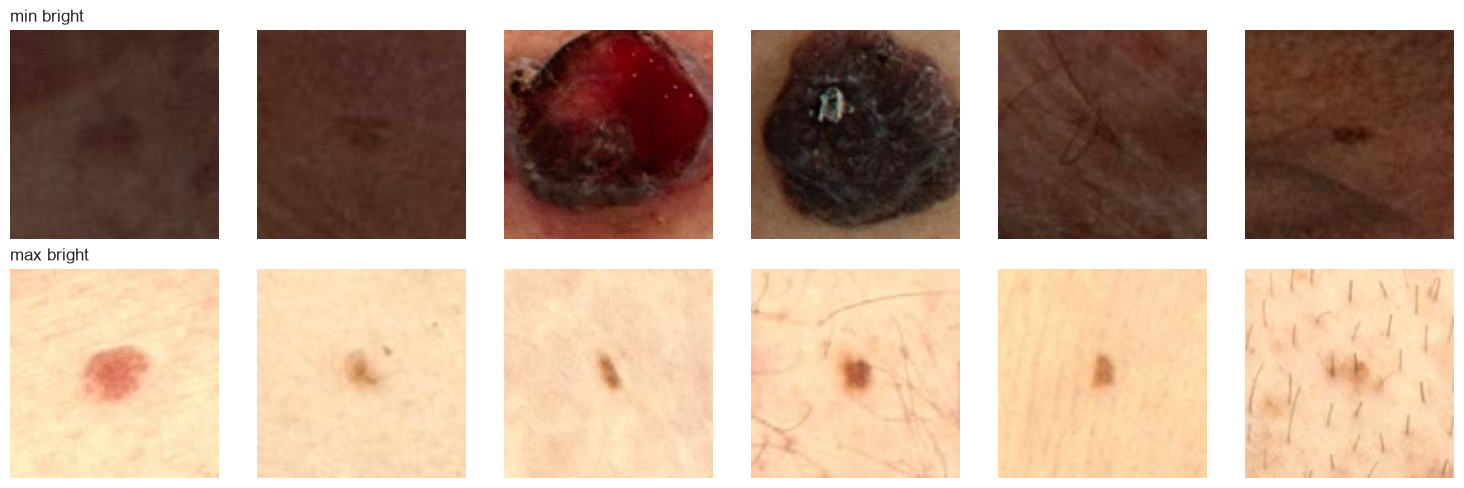

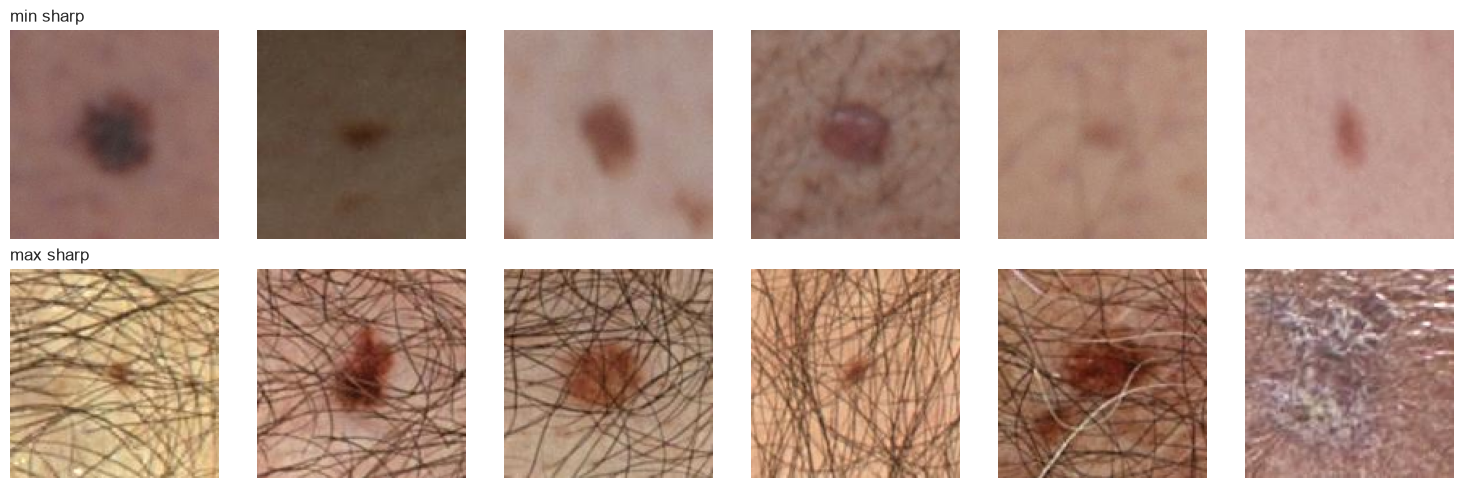

In [13]:
def extremes(col, k=6):
    lo, hi = feat.nsmallest(k, col).isic_id, feat.nlargest(k, col).isic_id
    fig, axes = plt.subplots(2, k, figsize=(15, 5))
    for r, ids in enumerate([lo, hi]):
        for a, i in zip(axes[r], ids):
            a.imshow(Image.open(IMG_DIR / f"{i}.jpg")); a.axis("off")
        axes[r, 0].set_title("min " + col if r == 0 else "max " + col, loc="left")
    plt.tight_layout(); plt.show()

extremes("bright"); extremes("sharp")

## 4б. Трудные примеры: malignant, похожие на benign
Для каждого malignant ищем ближайший benign в пространстве статистик (яркость, контраст, резкость, R, G, B; z-нормировка). В верхней строке malignant, в нижней — его двойник.

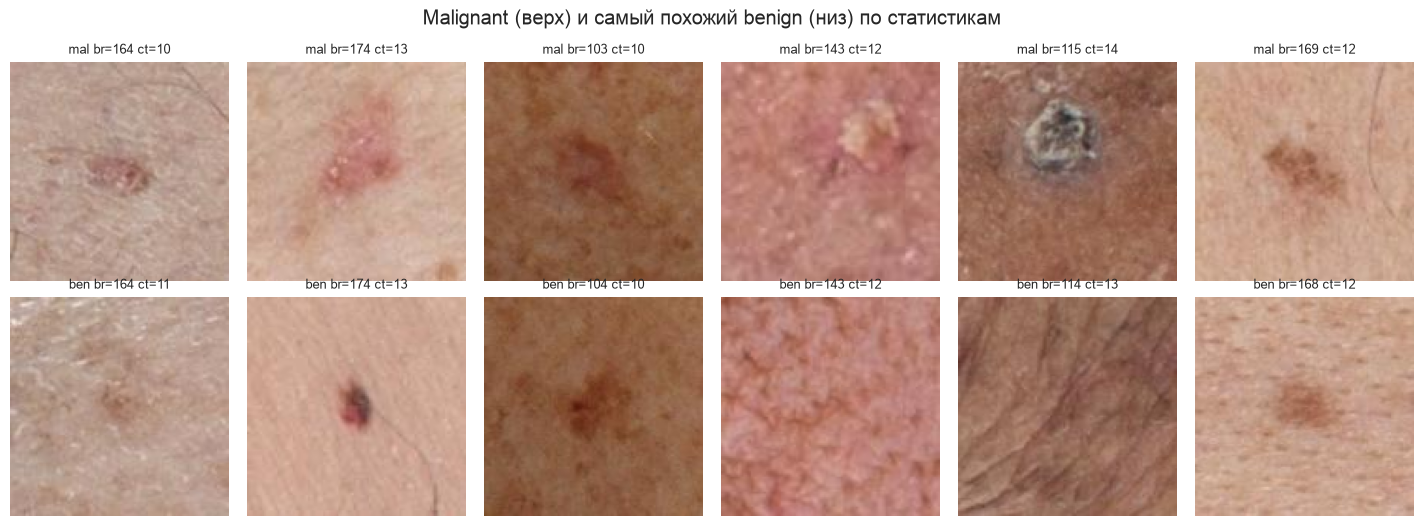

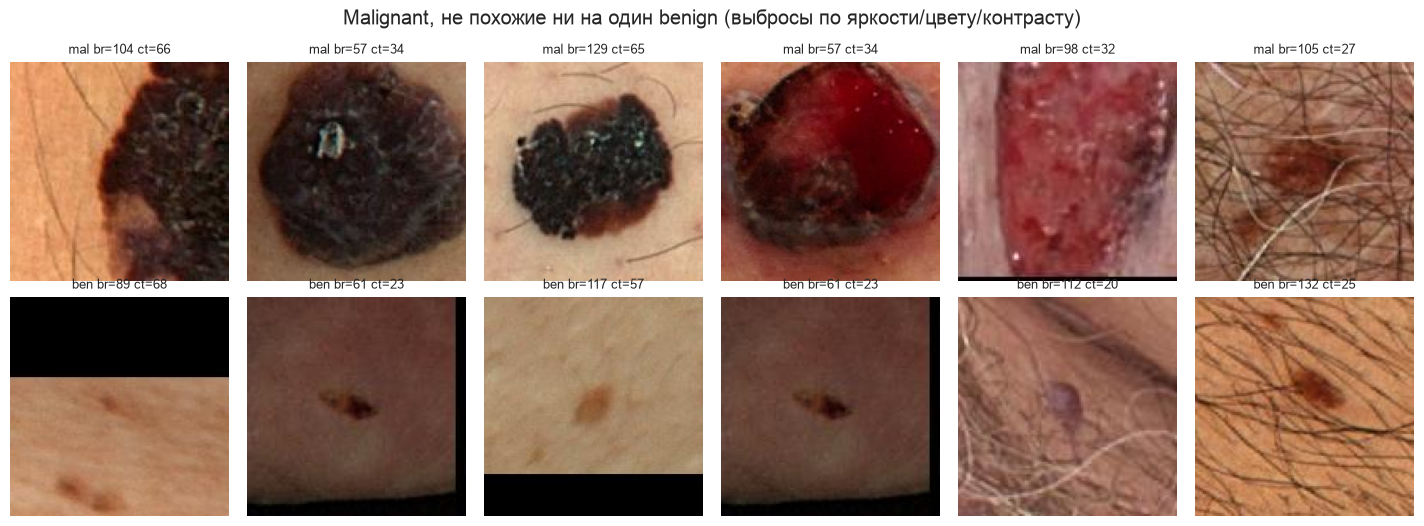

медиана расстояния до ближайшего benign: 0.30; доля malignant, у которых benign-двойник ближе 0.2σ: 19%


In [14]:
# Трудные примеры: для каждого malignant ищем ближайший benign в пространстве (яркость, контраст, резкость, R, G, B)
fc = ["bright", "contrast", "sharp", "R", "G", "B"]
Z = (feat[fc] - feat[fc].mean()) / feat[fc].std()
mi, bi = feat.index[feat.target == 1], feat.index[feat.target == 0]
Dm = np.linalg.norm(Z.loc[mi].values[:, None] - Z.loc[bi].values[None], axis=2)
nn_dist = Dm.min(1); nn_ben = bi[Dm.argmin(1)]

def tile(idx, title, partner=None, k=6):
    rows = 2 if partner is not None else 1
    fig, axes = plt.subplots(rows, k, figsize=(2.4 * k, 2.7 * rows), squeeze=False)
    for c, j in enumerate(idx[:k]):
        for r, jj in enumerate([j] + ([partner[c]] if partner is not None else [])):
            axes[r, c].imshow(load_img(feat.isic_id[jj])); axes[r, c].axis("off")
            axes[r, c].set_title(f"{feat.label[jj][:3]} br={feat.bright[jj]:.0f} ct={feat.contrast[jj]:.0f}", fontsize=9)
    fig.suptitle(title); plt.tight_layout(); plt.show()

order = np.argsort(nn_dist)
tile(mi[order[:6]], "Malignant (верх) и самый похожий benign (низ) по статистикам", nn_ben[order[:6]])
tile(mi[order[-6:]], "Malignant, не похожие ни на один benign (выбросы по яркости/цвету/контрасту)", nn_ben[order[-6:]])

# сколько malignant «теряются» среди benign
thr = np.median(nn_dist)
print(f"медиана расстояния до ближайшего benign: {thr:.2f}; доля malignant, у которых benign-двойник ближе 0.2σ: {(nn_dist < 0.2).mean()*100:.0f}%")

**Что видно:**
- Для **19%** malignant есть benign-двойник ближе 0.2σ по этим статистикам. На картинках это бледно-розовые или коричневые пятна без выраженной структуры: по яркости и цвету, а часто и на глаз, они неотличимы от benign (1-я и 6-я пары). Именно эти случаи будут главным источником ошибок, и простые признаки здесь бесполезны. Нужны текстура и форма, то есть сверточная сеть или крупные признаки.
- Есть и обратная группа: крупные, тёмные, асимметричные, с изъязвлением или красной зоной поражения, которые заполняют весь кроп (яркость 57–130, контраст 27–66). Ближайший benign для них совсем не похож (мелкие пятна на коже, часто с чёрными полями), расстояние велико. Такие malignant распознать легко.
- Статистики яркости и контраста, судя по примерам, сильно зависят от **размера поражения в кадре**. Поэтому различие медиан между классами из раздела 2 во многом отражает размер, а не «цвет» как таковой.

## 5. Средние изображения классов (ресайз 128×128)

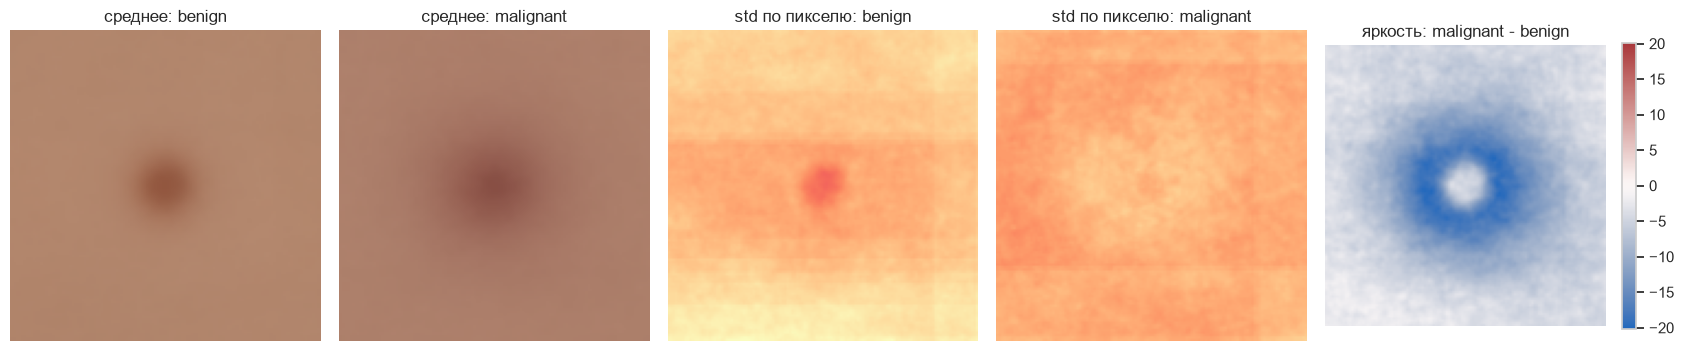

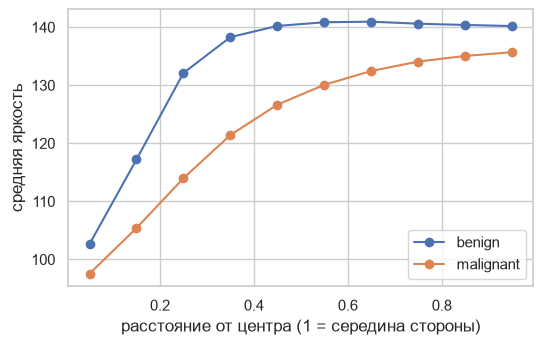

benign     центр 123.8 | периферия 140.1 | центр темнее периферии у 96% снимков
malignant  центр 109.3 | периферия 135.7 | центр темнее периферии у 93% снимков


In [15]:
# одинаковое число снимков в классах: все 393 malignant и 393 случайных benign
S = 128
def load_s(i): return np.asarray(Image.open(IMG_DIR / f"{i}.jpg").convert("RGB").resize((S, S), Image.BILINEAR), dtype=np.float32)
ids = {"benign": ben.isic_id.iloc[:393].tolist(), "malignant": mal.isic_id.tolist()}
stack = {k: np.stack([load_s(i) for i in v]) for k, v in ids.items()}
mean = {k: v.mean(0) for k, v in stack.items()}
std = {k: v.std(0).mean(-1) for k, v in stack.items()}

fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for j, k in enumerate(["benign", "malignant"]):
    ax[j].imshow(mean[k].astype(np.uint8)); ax[j].set_title(f"среднее: {k}")
for j, k in enumerate(["benign", "malignant"]):
    im = ax[2 + j].imshow(std[k], cmap="magma", vmin=0, vmax=max(s.max() for s in std.values())); ax[2 + j].set_title(f"std по пикселю: {k}")
diff = mean["malignant"].mean(-1) - mean["benign"].mean(-1)
v = np.abs(diff).max(); d = ax[4].imshow(diff, cmap="vlag", vmin=-v, vmax=v); ax[4].set_title("яркость: malignant - benign")
for a in ax: a.axis("off")
plt.colorbar(d, ax=ax[4], fraction=0.046); plt.tight_layout(); plt.show()

# радиальный профиль яркости: от центра кропа к краю
yy, xx = np.mgrid[:S, :S]; rad = np.hypot(yy - S / 2 + .5, xx - S / 2 + .5) / (S / 2)
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(6, 3.6))
for k in stack:
    g = stack[k].mean(-1)                       # (n, S, S)
    prof = [g[:, (rad >= lo) & (rad < hi)].mean() for lo, hi in zip(bins[:-1], bins[1:])]
    ax.plot((bins[:-1] + bins[1:]) / 2, prof, marker="o", label=k)
ax.set_xlabel("расстояние от центра (1 = середина стороны)"); ax.set_ylabel("средняя яркость"); ax.legend(); plt.show()

# центр против периферии у каждого снимка
c = {k: (v.mean(-1)[:, rad < 0.3].mean(1), v.mean(-1)[:, rad > 0.8].mean(1)) for k, v in stack.items()}
for k, (cen, per) in c.items():
    print(f"{k:10s} центр {cen.mean():.1f} | периферия {per.mean():.1f} | центр темнее периферии у {(cen < per).mean()*100:.0f}% снимков")

**Что видно:**
- Оба средних изображения — тёмное круглое пятно ровно в центре на фоне кожи, без смещения: **поражение центрировано** (центр темнее периферии у 96% benign и 93% malignant).
- У malignant пятно **шире и темнее**: яркость в центре 109 против 124, на периферии 136 против 140. На карте разности темнее весь диск радиусом ≈0.6 от центра, а в самом центре разница минимальна (там и у benign темно). Профиль яркости у benign выходит на плато уже на радиусе ≈0.4, у malignant растёт заметно дольше. Это согласуется с тем, что malignant в среднем крупнее в кадре.
- Карта std: у benign пик изменчивости строго в центре (все пятна маленькие и компактные), у malignant изменчивость размазана по всему кропу (разный размер и форма, больше волос и фона).
- Следствия: центрированный кроп и flip/rotate безопасны, но агрессивный random-resized-crop может срезать краевые части крупных поражений и стереть признак «размер»; зум лучше ограничить и сравнить с вариантом без него. Средние изображения усредняют по 393 снимка в каждом классе, benign взяты первыми 393 из случайной выборки.

## 6. Нормализация по цвету и яркости
Два шага для каждого снимка:
1. **Цвет — gray-world:** масштабируем каналы R, G, B так, чтобы их средние совпали (убираем общий цветовой оттенок съёмки).
2. **Яркость — стандартизация канала L (LAB):** приводим среднее и стандартное отклонение L каждого снимка к целевым значениям (медианы по выборке). Цветность (a, b) не трогаем.

In [16]:
def gray_world(im):
    x = im.astype(np.float32)
    m = x.reshape(-1, 3).mean(0)
    x *= m.mean() / np.maximum(m, 1e-6)
    return np.clip(x, 0, 255).astype(np.uint8)

def norm_brightness(im, mu, sd):
    lab = cv2.cvtColor(im, cv2.COLOR_RGB2LAB).astype(np.float32)
    L = lab[..., 0]
    lab[..., 0] = np.clip((L - L.mean()) / (L.std() + 1e-6) * sd + mu, 0, 255)
    return cv2.cvtColor(lab.astype(np.uint8), cv2.COLOR_LAB2RGB)

def load(i): return np.asarray(Image.open(IMG_DIR / f"{i}.jpg").convert("RGB"))

# целевые mu, sd для L — медианы по выборке
Ls = [cv2.cvtColor(load(i), cv2.COLOR_RGB2LAB)[..., 0] for i in smp.isic_id[::10]]
MU, SD = np.median([l.mean() for l in Ls]), np.median([l.std() for l in Ls])
print(f"целевая L: mean={MU:.1f}, std={SD:.1f}")

def normalize(im): return norm_brightness(gray_world(im), MU, SD)

целевая L: mean=151.0, std=11.6


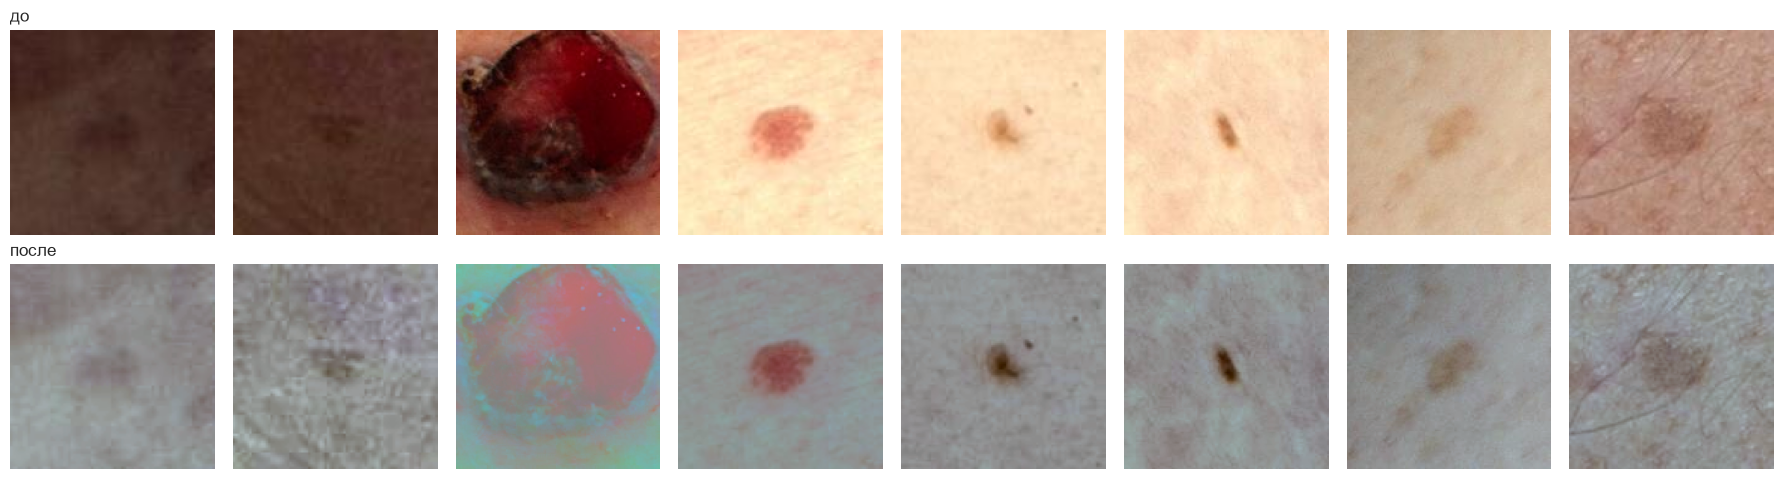

In [17]:
# до / после: самые тёмные, самые светлые и случайные снимки
pick = list(feat.nsmallest(3, "bright").isic_id) + list(feat.nlargest(3, "bright").isic_id) + list(feat.sample(2, random_state=1).isic_id)
fig, axes = plt.subplots(2, len(pick), figsize=(18, 5))
for c, i in enumerate(pick):
    im = load(i)
    axes[0, c].imshow(im); axes[1, c].imshow(normalize(im))
    axes[0, c].axis("off"); axes[1, c].axis("off")
axes[0, 0].set_title("до", loc="left"); axes[1, 0].set_title("после", loc="left")
plt.tight_layout(); plt.show()

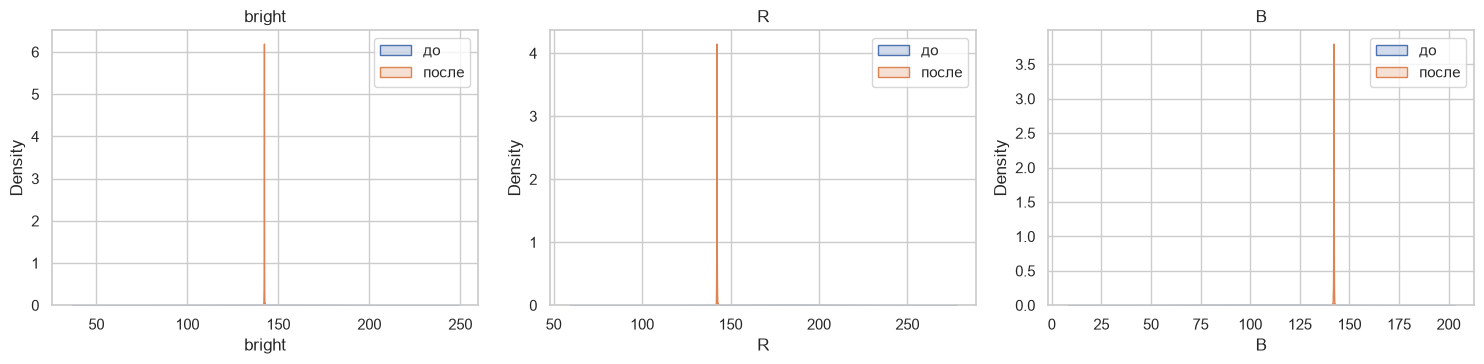

std по выборке:
             до  после
bright    30.25   0.09
contrast   8.84   0.20
R         32.69   0.13
G         30.36   0.09
B         28.03   0.13


In [18]:
# разброс признаков по выборке до и после
sub = smp.sample(800, random_state=0)
def feats(im):
    g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY); r, gr, b = im.reshape(-1, 3).mean(0)
    return dict(bright=g.mean(), contrast=g.std(), R=r, G=gr, B=b)
before = pd.DataFrame([feats(load(i)) for i in sub.isic_id])
after = pd.DataFrame([feats(normalize(load(i))) for i in sub.isic_id])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c in zip(axes, ["bright", "R", "B"]):
    sns.kdeplot(before[c], label="до", fill=True, ax=a); sns.kdeplot(after[c], label="после", fill=True, ax=a)
    a.set_title(c); a.legend()
plt.tight_layout(); plt.show()
print("std по выборке:"); print(pd.DataFrame({"до": before.std(), "после": after.std()}).round(2))

После нормализации разброс яркости и цветовых каналов между снимками заметно сокращается, а тёмные и светлые кадры становятся сопоставимыми.

**Осторожно:** malignant в среднем темнее и контрастнее benign (см. раздел 2), поэтому жёсткая поэкземплярная нормализация может убрать часть полезного сигнала. Стоит сравнить модель с нормализацией и без неё, а параметры (`MU`, `SD`) считать только по train.

## 7. Выводы
- Снимки — **квадратные кропы** разного размера (65–237 px, медиана 131) → ресайз до единого разрешения; по классам размер почти не различается.
- Цветовые/яркостные статистики классы почти не разделяют (сильное перекрытие), визуально malignant от benign отличить трудно → нужны модели, а не простые правила.
- Есть вариативность яркости, цвета и резкости (в т.ч. тёмные и размытые кадры) → нормализация, цветовые аугментации, flip/rotate (поражения не имеют выделенной ориентации).
- Поражение расположено в центре кропа, фон — кожа.
- Артефакты: волосы (≈7% снимков с сильным покрытием) и чёрные поля (≈3%), у malignant чаще → маскирование/аугментации и проверка по срезам; точных дубликатов в выборке нет, утечку по пациентам проверять на полном наборе.
- Средние изображения подтверждают центрирование поражения; у malignant оно шире и темнее (крупнее в кадре) → не использовать сильный random-resized-crop.
- Часть malignant (≈19%) по яркости и цвету неотличима от benign — нужна модель, работающая с текстурой и формой, а не со статистиками.
